# EpiShield AI — Data Understanding & EDA

This notebook explores the Italian epidemic data before feature engineering or model development. It reads the project's existing `Processed Data` files and examines data coverage, quality, case and death trends, and differences between regions.

**Analysis scope:** Daily regional and national data, population by region and age group, and source notes. Negative and blank values are flagged for review and are not changed automatically.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid', context='notebook')

# Locate project root from the notebook's current folder (works from project root or this folder).
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / 'Src' / 'Processed Data').is_dir():
        PROJECT_DIR = candidate
        break
else:
    raise FileNotFoundError('Could not locate Src/Processed Data. Run this notebook from the project or one of its subfolders.')

DATA_DIR = PROJECT_DIR / 'Src' / 'Processed Data'
EDA_DIR = PROJECT_DIR / 'Src' / 'Data Engineering' / 'outputs' / 'eda'
FIGURE_DIR = EDA_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print('Project:', PROJECT_DIR)
print('Input data:', DATA_DIR)
print('EDA outputs:', EDA_DIR)


Project: D:\DEPI\EpiShield-AI
Input data: D:\DEPI\EpiShield-AI\Src\Processed Data
EDA outputs: D:\DEPI\EpiShield-AI\Src\Data Engineering\outputs\eda


## 1. Load and inspect the data

Blank values are preserved initially so they can be counted explicitly. Numeric fields and dates are converted for analysis in later cells.


In [2]:
files = {
    'regional': 'regional_clean.csv',
    'national': 'national_clean.csv',
    'population': 'population_clean.csv',
    'notes': 'notes_clean.csv',
}
data = {name: pd.read_csv(DATA_DIR / filename, dtype='string', keep_default_na=False) for name, filename in files.items()}
regional, national, population, notes = (data[k].copy() for k in ('regional', 'national', 'population', 'notes'))

overview = pd.DataFrame([
    {'Dataset': name.title(), 'Rows': len(df), 'Columns': len(df.columns), 'Column names': ', '.join(df.columns)}
    for name, df in data.items()
])
display(overview[['Dataset', 'Rows', 'Columns']])
display(regional.head())


,Dataset,Rows,Columns
0,Regional,37401,30
1,National,1781,24
2,Population,210,12
3,Notes,1617,2


,data,stato,codice_regione,denominazione_regione,lat,long,ricoverati_con_sintomi,terapia_intensiva,totale_ospedalizzati,isolamento_domiciliare,totale_positivi,variazione_totale_positivi,nuovi_positivi,dimessi_guariti,deceduti,casi_da_sospetto_diagnostico,casi_da_screening,totale_casi,tamponi,casi_testati,note,ingressi_terapia_intensiva,note_test,note_casi,totale_positivi_test_molecolare,totale_positivi_test_antigenico_rapido,tamponi_test_molecolare,tamponi_test_antigenico_rapido,codice_nuts_1,codice_nuts_2
0,2020-02-24 18:00:00,ITA,13,Abruzzo,42.35122196,13.39843823,0,0,0,0,0,0,0,0,0,,,0,5,,,,,,,,,,,
1,2020-02-24 18:00:00,ITA,17,Basilicata,40.63947052,15.80514834,0,0,0,0,0,0,0,0,0,,,0,0,,,,,,,,,,,
2,2020-02-24 18:00:00,ITA,18,Calabria,38.90597598,16.59440194,0,0,0,0,0,0,0,0,0,,,0,1,,,,,,,,,,,
3,2020-02-24 18:00:00,ITA,15,Campania,40.83956555,14.25084984,0,0,0,0,0,0,0,0,0,,,0,10,,,,,,,,,,,
4,2020-02-24 18:00:00,ITA,08,Emilia-Romagna,44.49436681,11.341720800000001,10,2,12,6,18,0,18,0,0,,,18,148,,,,,,,,,,,


### Short glossary of fields used

- `data`: Reporting date.
- `denominazione_regione`: Region name.
- `nuovi_positivi`: Newly reported positive cases for the day.
- `deceduti`: Cumulative reported deaths, not deaths for that day.
- `totale_casi`: Cumulative reported cases.
- `totale_generale`: Population for an age-group row; values are summed by region before comparison.

**Note:** Do not sum cumulative `deceduti` values across dates. Use the latest value per region for a cumulative total, or calculate date-to-date differences when analyzing daily changes.


## 2. Data quality checks

The report distinguishes `NaN` from blank text values and checks duplicates, dates, and the (date, region) key. A blank field does not mean its value is zero.


In [3]:
quality_rows = []
for name, df in data.items():
    blank_cells = df.apply(lambda col: col.astype('string').str.strip().eq('').sum()).sum()
    quality_rows.append({
        'Dataset': name.title(), 'Rows': len(df), 'Columns': len(df.columns),
        'Duplicate full rows': int(df.duplicated().sum()), 'Blank cells': int(blank_cells),
        'Exact empty columns': int((df.astype('string').apply(lambda c: c.str.strip().eq('').sum()) > 0).sum()),
    })
quality_report = pd.DataFrame(quality_rows)
display(quality_report)

# Normalize blanks for analysis; retain raw source tables in `data`.
for key, df in data.items():
    data[key] = df.replace(r'^\s*$', pd.NA, regex=True)
regional, national, population, notes = (data[k].copy() for k in ('regional', 'national', 'population', 'notes'))

for df in (regional, national, notes):
    df['data_parsed'] = pd.to_datetime(df['data'], errors='coerce')
regional['region_code'] = regional['codice_regione'].astype('string').str.strip()
regional['region_name'] = regional['denominazione_regione'].astype('string').str.strip()
population['region_code'] = population['codice_regione'].astype('string').str.strip().str.lstrip('0')
regional['region_code_norm'] = regional['region_code'].str.lstrip('0')

numeric_candidates = [c for c in regional.columns if c not in {'data', 'stato', 'denominazione_regione', 'note', 'note_test', 'note_casi', 'codice_nuts_1', 'codice_nuts_2', 'region_code', 'region_name', 'region_code_norm', 'data_parsed'}]
numeric_parse_rows = []
for col in numeric_candidates:
    raw = regional[col]
    parsed = pd.to_numeric(raw, errors='coerce')
    numeric_parse_rows.append({'Column': col, 'Blank source values': int(raw.isna().sum()), 'Nonblank values that fail numeric conversion': int((raw.notna() & parsed.isna()).sum())})
numeric_parse_report = pd.DataFrame(numeric_parse_rows)
display(numeric_parse_report.sort_values('Blank source values', ascending=False).head(15))

regional['cases_new'] = pd.to_numeric(regional['nuovi_positivi'], errors='coerce')
regional['deaths_cumulative'] = pd.to_numeric(regional['deceduti'], errors='coerce')
regional['cases_cumulative'] = pd.to_numeric(regional['totale_casi'], errors='coerce')
regional['date'] = regional['data_parsed'].dt.normalize()

key_duplicates = regional.duplicated(['date', 'region_code_norm'], keep=False) if {'date','region_code_norm'} <= set(regional.columns) else pd.Series(dtype=bool)
date_quality = pd.DataFrame([{
    'Rows with invalid date': int(regional['date'].isna().sum()),
    'Duplicate date-region rows': int(key_duplicates.sum()),
    'Regions': int(regional['region_name'].nunique()),
    'Unique reporting dates': int(regional['date'].nunique()),
    'First date': regional['date'].min(), 'Last date': regional['date'].max(),
}])
display(date_quality)

negative_cases = regional.loc[regional['cases_new'] < 0, ['date', 'region_name', 'cases_new', 'note', 'note_casi']].sort_values('date')
print('Negative reported new-case values:', len(negative_cases))
display(negative_cases)

# Conservative policy: preserve source values and flag invalid count targets.
negative_cases = negative_cases.copy()
has_note_code = (negative_cases['note'].fillna('').str.match(r'^dc-IT-\d+') |
                 negative_cases['note_casi'].fillna('').str.match(r'^dc-IT-\d+'))
has_note_text = (negative_cases['note'].fillna('').str.strip().ne('') |
                 negative_cases['note_casi'].fillna('').str.strip().ne(''))
negative_cases['row_note_status'] = np.select(
    [has_note_code, has_note_text],
    ['Source note code present; linked explanation not resolved', 'Descriptive note present on source row'],
    default='No row-level explanation present'
)
negative_cases['eda_decision'] = 'Keep reported value for source-faithful EDA; flag for review.'
negative_cases['count_model_decision'] = 'Not a valid non-negative count target; exclude this target observation until a documented reconciliation rule is approved. Do not clip to zero.'

required_fields = ['date', 'region_code_norm', 'region_name', 'cases_new']
core_missing_rows = int(regional[required_fields].isna().any(axis=1).sum())
target_audit = regional[['date','region_code_norm','region_name','cases_new']].copy()
target_audit['negative_target_flag'] = target_audit['cases_new'].lt(0)
target_audit['valid_nonnegative_count_target'] = target_audit['cases_new'].ge(0)

availability_rows = []
for col in regional.columns:
    if col in {'data','data_parsed','date','region_code','region_code_norm','region_name'}:
        continue
    values = regional[col].astype('string').str.strip()
    present = values.notna() & values.ne('')
    if present.sum() < len(regional):
        availability_rows.append({
            'Column': col, 'Available rows': int(present.sum()),
            'Blank rows': int((~present).sum()),
            'First available date': regional.loc[present, 'date'].min(),
            'Last available date': regional.loc[present, 'date'].max(),
        })
field_availability = pd.DataFrame(availability_rows).sort_values('Blank rows', ascending=False)
display(field_availability.head(20))
print('Rows missing any core EDA key/target field:', core_missing_rows)
print('Negative target rows flagged for count modeling:', int(target_audit['negative_target_flag'].sum()))

data_decisions = pd.DataFrame([
    {'Issue':'Core EDA fields (date, region, new cases)', 'Decision':'All source rows are retained. No imputation or row deletion; current core completeness check must be zero missing rows.', 'Reason':'These fields define the daily regional series.'},
    {'Issue':'Negative nuovi_positivi values', 'Decision':'Preserve reported values for EDA and reconciliation. Flag the 14 rows; exclude only these target observations from count-model training until an approved reconciliation rule exists. Do not replace with zero.', 'Reason':'A daily case count cannot be negative. Only some rows have an annotation, so the exact correction is not fully established.'},
    {'Issue':'Blank non-core indicators', 'Decision':'Keep as missing; do not fill with zero. Exclude period-limited indicators from an all-period baseline; only use them in a period where source availability is consistent and documented.', 'Reason':'Availability changes over time and blank does not mean zero.'},
    {'Issue':'Notes and note codes', 'Decision':'Keep for audit/context; do not use as numeric predictors or drop the underlying observation. Unresolved note codes remain unresolved.', 'Reason':'The processed note table does not provide a verified code-to-text mapping for every row.'},
    {'Issue':'Cumulative deaths', 'Decision':'Never sum cumulative deaths across dates. Use the last cumulative value for a period or date differences for daily change, and inspect revisions.', 'Reason':'Summing cumulative snapshots double-counts.'},
    {'Issue':'Population by age group', 'Decision':'Sum age-group rows by region before calculating per-capita rates.', 'Reason':'Population file has multiple age rows per region.'},
])
display(data_decisions)


,Dataset,Rows,Columns,Duplicate full rows,Blank cells,Exact empty columns
0,Regional,37401,30,0,213705,13
1,National,1781,24,0,10179,11
2,Population,210,12,0,0,0
3,Notes,1617,2,0,14,1


,Column,Blank source values,Nonblank values that fail numeric conversion
13,casi_da_screening,33999,0
12,casi_da_sospetto_diagnostico,33999,0
21,tamponi_test_antigenico_rapido,6846,0
20,tamponi_test_molecolare,6846,0
19,totale_positivi_test_antigenico_rapido,6846,0
18,totale_positivi_test_molecolare,6846,0
17,ingressi_terapia_intensiva,5943,0
16,casi_testati,1155,0
5,totale_ospedalizzati,0,0
4,terapia_intensiva,0,0


,Rows with invalid date,Duplicate date-region rows,Regions,Unique reporting dates,First date,Last date
0,0,0,21,1781,2020-02-24,2025-01-08


Negative reported new-case values: 14


,date,region_name,cases_new,note,note_casi
76,2020-02-27,Piemonte,-1,<NA>,<NA>
133,2020-03-01,Liguria,-17,<NA>,<NA>
154,2020-03-02,Liguria,-3,<NA>,<NA>
163,2020-03-02,Sicilia,-2,<NA>,<NA>
307,2020-03-09,Piemonte,-10,<NA>,<NA>
1115,2020-04-17,Calabria,-18,<NA>,<NA>
1485,2020-05-04,Sardegna,-2,dc-IT-0018,<NA>
1534,2020-05-07,Basilicata,-16,dc-IT-0022,<NA>
1555,2020-05-08,Basilicata,-1,dc-IT-0024,<NA>
1794,2020-05-19,Marche,-3,dc-IT-0032,<NA>


,Column,Available rows,Blank rows,First available date,Last available date
5,note_test,197,37204,2020-12-04,2024-08-22
1,casi_da_screening,3402,33999,2020-06-25,2020-12-03
0,casi_da_sospetto_diagnostico,3402,33999,2020-06-25,2020-12-03
6,note_casi,4634,32767,2020-12-04,2025-01-08
3,note,9839,27562,2020-03-07,2025-01-08
9,tamponi_test_molecolare,30555,6846,2021-01-15,2025-01-08
10,tamponi_test_antigenico_rapido,30555,6846,2021-01-15,2025-01-08
7,totale_positivi_test_molecolare,30555,6846,2021-01-15,2025-01-08
8,totale_positivi_test_antigenico_rapido,30555,6846,2021-01-15,2025-01-08
11,codice_nuts_1,30555,6846,2021-01-15,2025-01-08


Rows missing any core EDA key/target field: 0
Negative target rows flagged for count modeling: 14


,Issue,Decision,Reason
0,"Core EDA fields (date, region, new cases)",All source rows are retained. No imputation or...,These fields define the daily regional series.
1,Negative nuovi_positivi values,Preserve reported values for EDA and reconcili...,A daily case count cannot be negative. Only so...
2,Blank non-core indicators,Keep as missing; do not fill with zero. Exclud...,Availability changes over time and blank does ...
3,Notes and note codes,Keep for audit/context; do not use as numeric ...,The processed note table does not provide a ve...
4,Cumulative deaths,Never sum cumulative deaths across dates. Use ...,Summing cumulative snapshots double-counts.
5,Population by age group,Sum age-group rows by region before calculatin...,Population file has multiple age rows per region.


### Data quality decisions for this phase

**Negative values:** Keep the source-reported values for descriptive analysis and flag all 14 rows. Do not clip them to zero or delete source rows. Because a daily case count cannot be negative, these observations are excluded as targets for count-model training until a documented reconciliation rule is approved. Some rows have a note or note code, but the codes are not linked to verified explanations for every case; do not claim a confirmed cause for each value.

**Blank values:** Do not replace blanks with zero. Date, region, and new-case fields are complete in the current check, while testing, notes, and some indicators change in availability over time. Exclude period-limited indicators from a baseline covering all years and retain their missing values rather than inventing data. Do not delete a row because a note or non-core indicator is blank.

This policy preserves the source and gives the next phase explicit inputs. Any future correction/reconciliation rule must be documented before it is applied.


## 3. Time coverage and statistical summary

Calculate descriptive statistics for new cases, cumulative deaths, and cumulative cases. The new-case statistics include negative values as reported so the summary remains faithful to the source.


In [4]:
regional_numeric = regional[['cases_new', 'deaths_cumulative', 'cases_cumulative']]
statistical_summary = regional_numeric.describe(percentiles=[.25, .5, .75]).T
statistical_summary = statistical_summary.rename(columns={'count':'Count','mean':'Mean','std':'Std Dev','min':'Min','25%':'Q1','50%':'Median','75%':'Q3','max':'Max'})
display(statistical_summary.round(2))

daily_regional = (regional.dropna(subset=['date']).groupby('date', as_index=False)
                  .agg(new_cases=('cases_new','sum'), regions_reporting=('region_name','nunique'))
                  .sort_values('date'))
daily_regional['new_cases_7d_avg'] = daily_regional['new_cases'].rolling(7, min_periods=1).mean()

# National source is a separate aggregate; use it as a cross-check, not as rows to add to regional totals.
national['date'] = national['data_parsed'].dt.normalize()
national['cases_new'] = pd.to_numeric(national['nuovi_positivi'], errors='coerce')
national['deaths_cumulative'] = pd.to_numeric(national['deceduti'], errors='coerce')
national['cases_cumulative'] = pd.to_numeric(national['totale_casi'], errors='coerce')
national_daily = national[['date','cases_new','deaths_cumulative','cases_cumulative']].sort_values('date')
display(pd.DataFrame([{
    'Regional rows': len(regional), 'National dates': len(national_daily),
    'Regional date span': f"{regional['date'].min():%Y-%m-%d} — {regional['date'].max():%Y-%m-%d}",
    'National date span': f"{national_daily['date'].min():%Y-%m-%d} — {national_daily['date'].max():%Y-%m-%d}",
    'Regional daily cases total (sum across region rows)': regional['cases_new'].sum(),
    'National daily cases total (sum across days)': national_daily['cases_new'].sum(),
}]))


,Count,Mean,Std Dev,Min,Q1,Median,Q3,Max
cases_new,37401.0,712.86,1991.17,-229.0,14.0,99.0,526.0,52693.0
deaths_cumulative,37401.0,6911.11,8928.98,0.0,1063.0,3678.0,11186.0,48739.0
cases_cumulative,37401.0,744450.24,954327.09,0.0,60416.0,330846.0,1072356.0,4391944.0


,Regional rows,National dates,Regional date span,National date span,Regional daily cases total (sum across region rows),National daily cases total (sum across days)
0,37401,1781,2020-02-24 — 2025-01-08,2020-02-24 — 2025-01-08,26661679,26661679


## 4. National case and death trends

The first chart shows reported daily cases and a seven-day rolling mean to smooth daily reporting variation. The second chart shows source-reported cumulative deaths, which should generally trend upward.


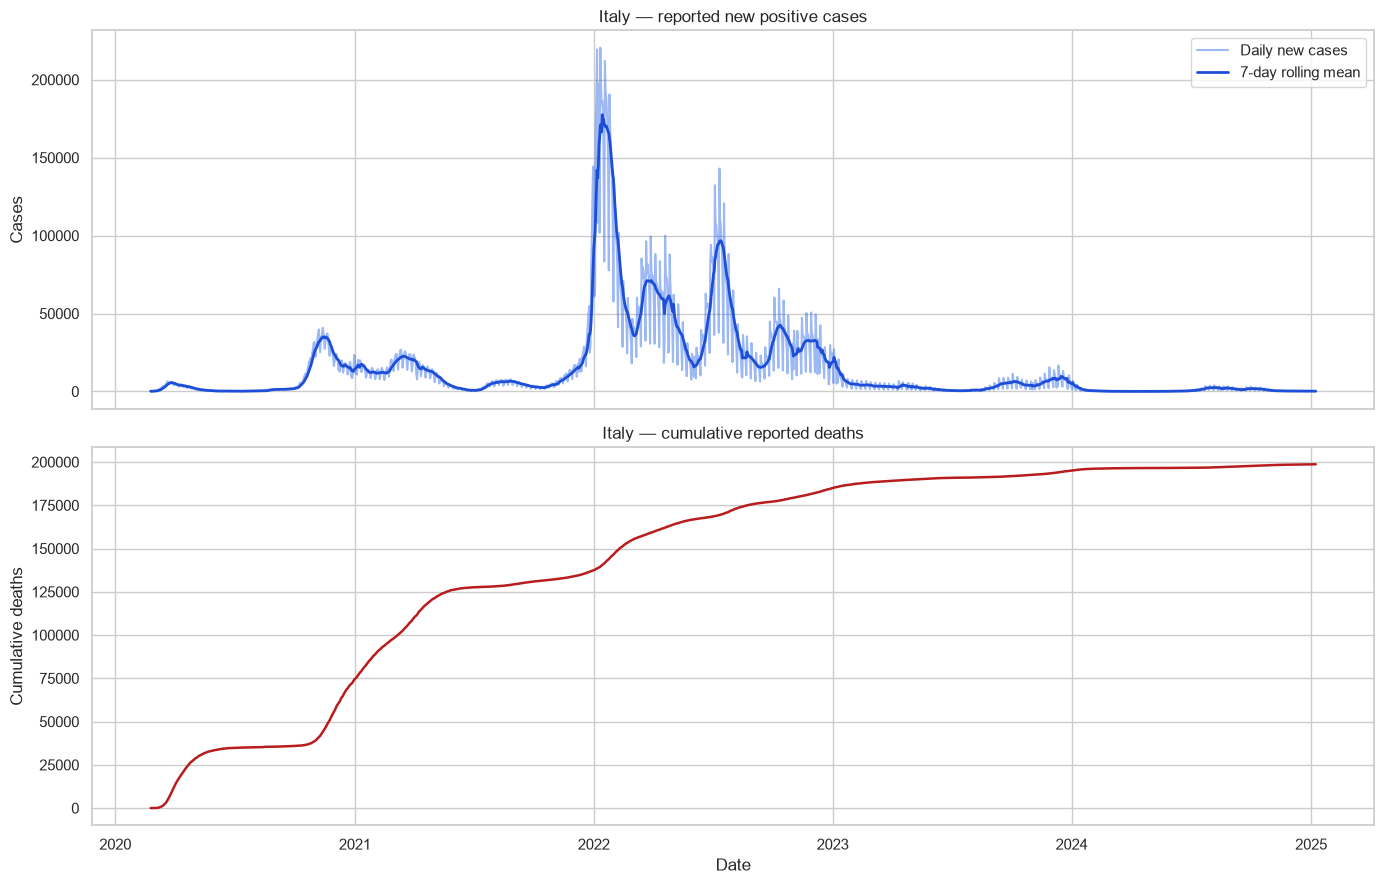

Top 10 reported daily case counts (verify reporting/revision context):


,date,cases_new
687,2022-01-11,220532
682,2022-01-06,219441
694,2022-01-18,212004
684,2022-01-08,197552
688,2022-01-12,196224
695,2022-01-19,192320
701,2022-01-25,190514
681,2022-01-05,189109
696,2022-01-20,188797
690,2022-01-14,186253


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
axes[0].plot(national_daily['date'], national_daily['cases_new'], color='#2563eb', alpha=.45, label='Daily new cases')
axes[0].plot(national_daily['date'], national_daily['cases_new'].rolling(7, min_periods=1).mean(), color='#1d4ed8', linewidth=2, label='7-day rolling mean')
axes[0].set_title('Italy — reported new positive cases')
axes[0].set_ylabel('Cases')
axes[0].legend()
axes[1].plot(national_daily['date'], national_daily['deaths_cumulative'], color='#b91c1c', linewidth=1.8)
axes[1].set_title('Italy — cumulative reported deaths')
axes[1].set_ylabel('Cumulative deaths')
axes[1].set_xlabel('Date')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'national_trends.png', dpi=160, bbox_inches='tight')
plt.show()

peak_rows = national_daily.nlargest(10, 'cases_new')[['date','cases_new']]
print('Top 10 reported daily case counts (verify reporting/revision context):')
display(peak_rows)


## 5. Regional comparison

Sum reported new cases across the observation period to rank regions descriptively. This is not a count of unique people or a risk measure. It is the sum of daily reports during the available period and may be affected by source corrections.


,region_code_norm,region_name,report_rows,dates,reported_new_cases_sum,latest_cumulative_cases,latest_cumulative_deaths,negative_case_days
15,3,Lombardia,1781,1781,4391545,4391944,48739,0
16,5,Veneto,1781,1781,2845290,2869014,17608,0
6,15,Campania,1781,1781,2573979,2575890,12169,1
3,12,Lazio,1781,1781,2561359,2562730,13331,0
19,8,Emilia-Romagna,1781,1781,2229998,2226840,20158,0
0,1,Piemonte,1781,1781,1823599,1820993,13937,2
20,9,Toscana,1781,1781,1669415,1669583,12724,0
10,19,Sicilia,1781,1781,1658437,1836915,13145,1
7,16,Puglia,1781,1781,1618438,1704918,10138,0
2,11,Marche,1781,1781,737674,737591,4568,1


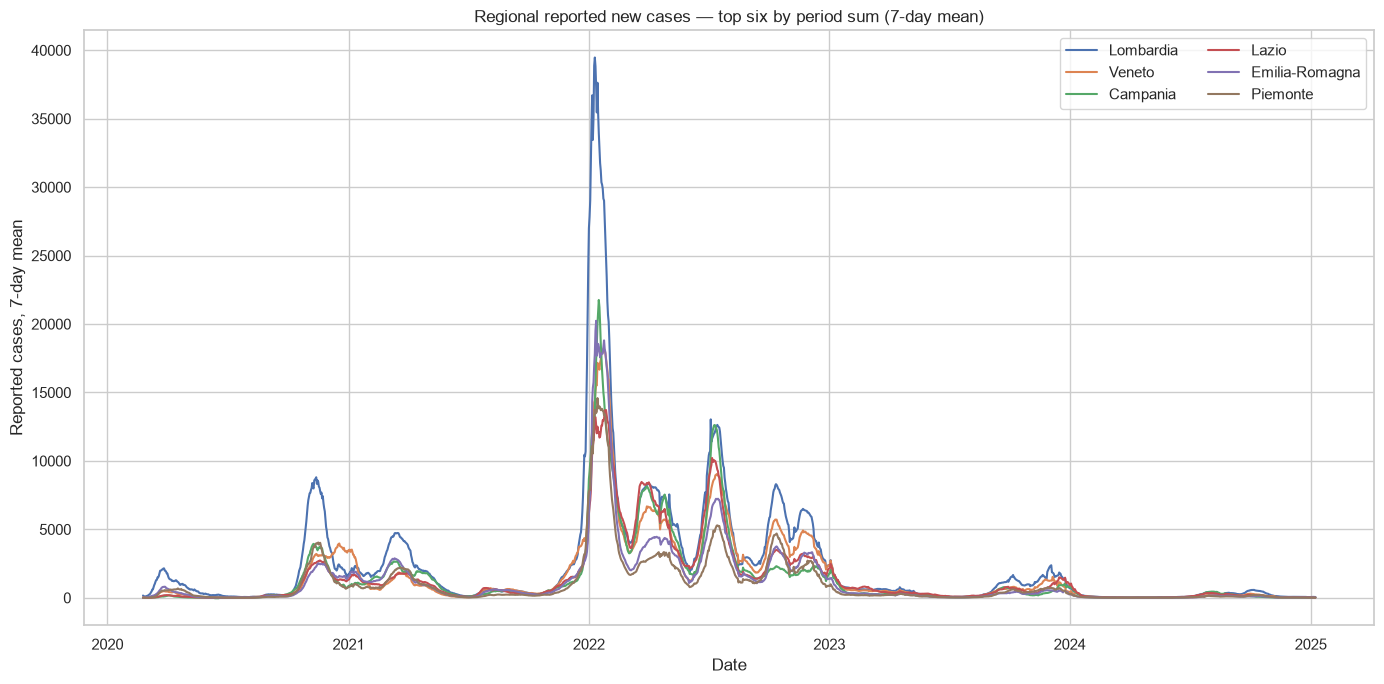

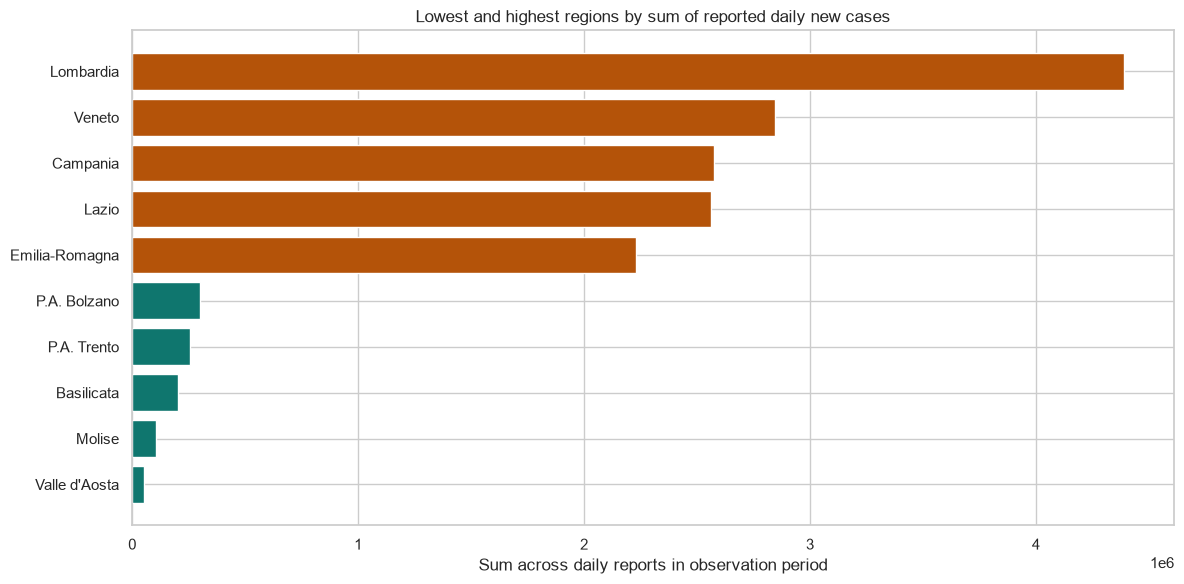

In [6]:
region_summary = (regional.groupby(['region_code_norm','region_name'], dropna=False)
                 .agg(report_rows=('date','size'), dates=('date','nunique'),
                      reported_new_cases_sum=('cases_new','sum'),
                      latest_cumulative_cases=('cases_cumulative','last'),
                      latest_cumulative_deaths=('deaths_cumulative','last'),
                      negative_case_days=('cases_new', lambda s: int((s < 0).sum())))
                 .reset_index())
display(region_summary.sort_values('reported_new_cases_sum', ascending=False).head(10))

top_names = region_summary.nlargest(6, 'reported_new_cases_sum')['region_name'].tolist()
regional_daily = (regional.groupby(['date','region_name'], as_index=False)['cases_new'].sum().sort_values('date'))
fig, ax = plt.subplots(figsize=(14, 7))
for name in top_names:
    part = regional_daily[regional_daily['region_name'] == name]
    ax.plot(part['date'], part['cases_new'].rolling(7, min_periods=1).mean(), linewidth=1.5, label=name)
ax.set_title('Regional reported new cases — top six by period sum (7-day mean)')
ax.set_xlabel('Date'); ax.set_ylabel('Reported cases, 7-day mean'); ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'regional_top6_trends.png', dpi=160, bbox_inches='tight')
plt.show()

top_bottom = pd.concat([region_summary.nsmallest(5,'reported_new_cases_sum').assign(Rank_group='Lowest'),
                        region_summary.nlargest(5,'reported_new_cases_sum').assign(Rank_group='Highest')])
fig, ax = plt.subplots(figsize=(12, 6))
plot_data = top_bottom.sort_values('reported_new_cases_sum')
ax.barh(plot_data['region_name'], plot_data['reported_new_cases_sum'], color=['#0f766e' if g=='Lowest' else '#b45309' for g in plot_data['Rank_group']])
ax.set_title('Lowest and highest regions by sum of reported daily new cases')
ax.set_xlabel('Sum across daily reports in observation period')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'regional_low_high.png', dpi=160, bbox_inches='tight')
plt.show()


## 6. Population-adjusted comparison — 2024 per 100,000 people

Sum population across age groups for each region, then compare reported new cases in calendar year 2024 per 100,000 people. This is an **approximate annual reporting rate** using the available population denominator. It is not a measure of current risk and may be affected by population changes and testing/reporting practices.


,region_code_norm,population,population_age_rows,region_name,reported_new_cases_2024,reported_cases_2024_per_100k
16,5,4879133,10,Veneto,35272,722.915321
3,12,5755700,10,Lazio,41063,713.431902
15,3,9597086,10,Lombardia,62073,646.790078
6,15,5712143,10,Campania,35086,614.235323
7,16,3953305,10,Puglia,22698,574.152513
4,13,1293941,10,Abruzzo,7120,550.256928
17,6,1206216,10,Friuli Venezia Giulia,6289,521.382572
20,9,3692555,10,Toscana,19019,515.063418
18,7,1524826,10,Liguria,7344,481.628724
1,10,870165,10,Umbria,4130,474.622629


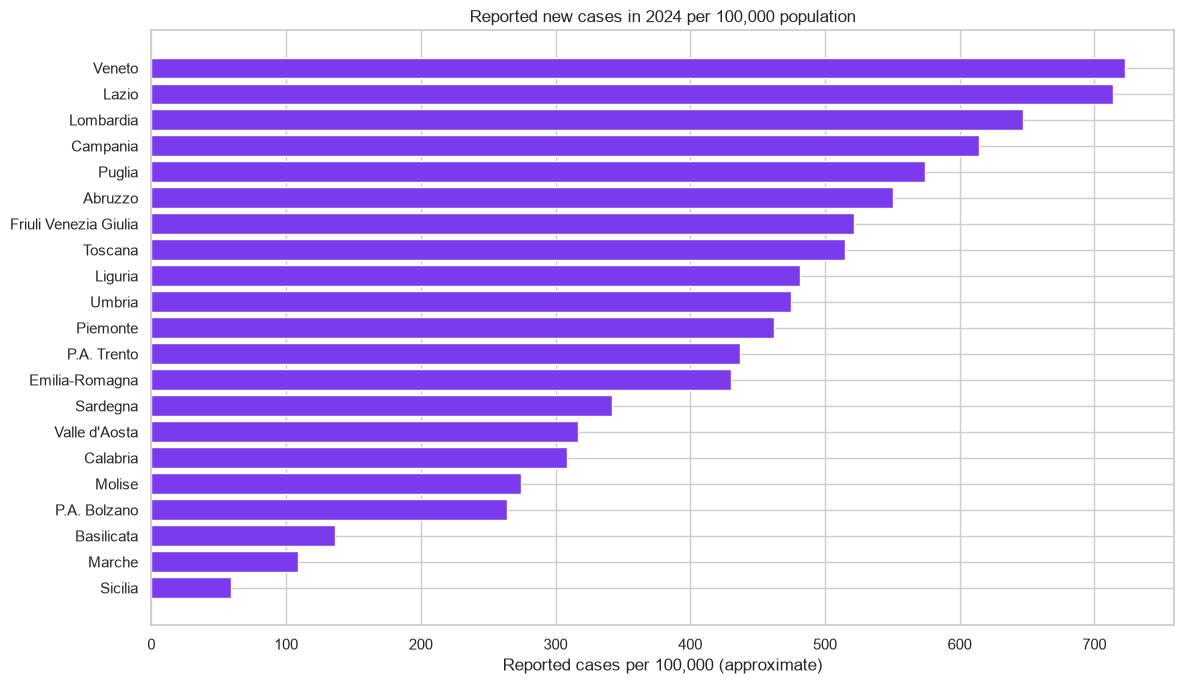

In [7]:
population['population_total'] = pd.to_numeric(population['totale_generale'], errors='coerce')
population['region_code_norm'] = population['region_code']
population_by_region = (population.groupby('region_code_norm', as_index=False)
                        .agg(population=('population_total','sum'),
                             population_age_rows=('range_eta','nunique')))
name_map = (regional[['region_code_norm','region_name']].drop_duplicates()
            .dropna(subset=['region_code_norm']))
population_by_region = population_by_region.merge(name_map, on='region_code_norm', how='left')

regional_2024 = regional[regional['date'].dt.year.eq(2024)]
cases_2024 = (regional_2024.groupby('region_code_norm', as_index=False)
              .agg(reported_new_cases_2024=('cases_new','sum')))
per_capita = population_by_region.merge(cases_2024, on='region_code_norm', how='left')
per_capita['reported_cases_2024_per_100k'] = per_capita['reported_new_cases_2024'] / per_capita['population'] * 100_000
display(per_capita.sort_values('reported_cases_2024_per_100k', ascending=False))

fig, ax = plt.subplots(figsize=(12, 7))
chart = per_capita.sort_values('reported_cases_2024_per_100k')
ax.barh(chart['region_name'], chart['reported_cases_2024_per_100k'], color='#7c3aed')
ax.set_title('Reported new cases in 2024 per 100,000 population')
ax.set_xlabel('Reported cases per 100,000 (approximate)')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'regional_2024_per_100k.png', dpi=160, bbox_inches='tight')
plt.show()


## 7. Regional-to-national consistency check

The national and regional datasets are separate source tables. Compare the sum of daily regional cases with the national figure to identify possible differences; never add the two together. Do not assume an exact match until source definitions and reporting times have been checked.


,date,new_cases,cases_new,difference_regional_minus_national,absolute_difference
0,2020-02-24,221,221,0,0
1,2020-02-25,93,93,0,0
2,2020-02-26,78,78,0,0
3,2020-02-27,250,250,0,0
4,2020-02-28,238,238,0,0
5,2020-02-29,240,240,0,0
6,2020-03-01,566,566,0,0
7,2020-03-02,342,342,0,0
8,2020-03-03,466,466,0,0
9,2020-03-04,587,587,0,0


Mean absolute daily difference: 0.0


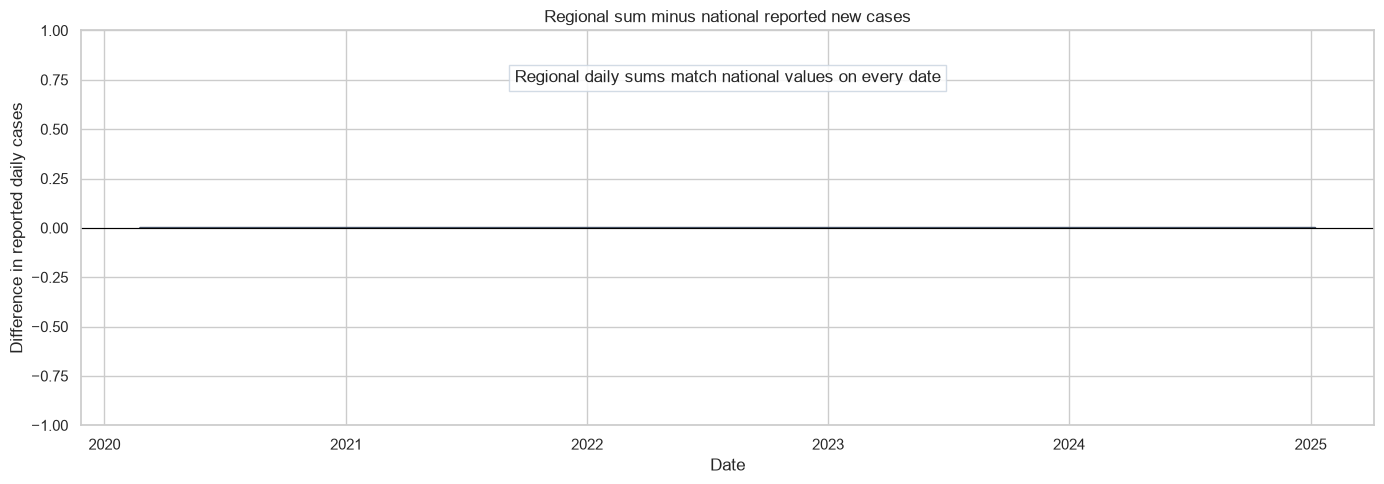

In [8]:
regional_national_compare = (daily_regional[['date','new_cases']]
    .merge(national_daily[['date','cases_new']], on='date', how='outer', suffixes=('_regional_sum','_national'))
    .sort_values('date'))
regional_national_compare['difference_regional_minus_national'] = regional_national_compare['new_cases'] - regional_national_compare['cases_new']
regional_national_compare['absolute_difference'] = regional_national_compare['difference_regional_minus_national'].abs()
display(regional_national_compare.nlargest(10, 'absolute_difference'))
print('Mean absolute daily difference:', round(regional_national_compare['absolute_difference'].mean(), 2))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(regional_national_compare['date'], regional_national_compare['difference_regional_minus_national'], color='#475569')
ax.axhline(0, color='black', linewidth=.8)
ax.set_title('Regional sum minus national reported new cases')
ax.set_ylabel('Difference in reported daily cases'); ax.set_xlabel('Date')
if regional_national_compare['absolute_difference'].max() == 0:
    ax.set_ylim(-1, 1)
    ax.text(.5, .88, 'Regional daily sums match national values on every date', transform=ax.transAxes, ha='center', va='center', bbox={'facecolor':'white','alpha':.85,'edgecolor':'#cbd5e1'})
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'regional_national_difference.png', dpi=160, bbox_inches='tight')
plt.show()


## 8. Findings and decisions before feature engineering

The decisions below are applied in the audit tables saved later in this notebook and define what can be used in the next phase.

### Findings from the data review

- The regional dataset contains 37,401 rows (21 regions × 1,781 reporting dates).
- There are 14 negative new-case values. They are flagged and neither clipped nor deleted. Exclude them as count-model targets until a documented reconciliation rule is approved.
- Date, region, and new-case fields are complete in the current check. Blank non-core fields remain missing and are not filled with zero.
- Indicators available for only part of the period are excluded from an all-years baseline.
- `deceduti` is cumulative and must not be summed across dates to obtain total deaths.
- The population file has multiple age-group rows per region; aggregate them before calculating rates.
- Daily regional case sums match the national source on every date in the current files.

One decision is deferred to model development: if a count model requires a fully non-negative target series, choose and document a correction/reconciliation method and its impact before training.


## 9. Save tables and reports

Summary tables and figures are saved under `outputs/eda` for review and presentation. The original data files are not overwritten.


In [9]:
quality_report.to_csv(EDA_DIR / 'data_quality_report.csv', index=False, encoding='utf-8-sig')
numeric_parse_report.to_csv(EDA_DIR / 'numeric_parse_report.csv', index=False, encoding='utf-8-sig')
field_availability.to_csv(EDA_DIR / 'field_availability.csv', index=False, encoding='utf-8-sig')
data_decisions.to_csv(EDA_DIR / 'data_decision_log.csv', index=False, encoding='utf-8-sig')
negative_cases.to_csv(EDA_DIR / 'negative_case_review.csv', index=False, encoding='utf-8-sig')
target_audit.to_csv(EDA_DIR / 'count_target_audit.csv', index=False, encoding='utf-8-sig')
statistical_summary.to_csv(EDA_DIR / 'statistical_summary.csv', encoding='utf-8-sig')
region_summary.to_csv(EDA_DIR / 'regional_summary.csv', index=False, encoding='utf-8-sig')
per_capita.to_csv(EDA_DIR / 'regional_2024_per_100k.csv', index=False, encoding='utf-8-sig')
regional_national_compare.to_csv(EDA_DIR / 'regional_national_daily_comparison.csv', index=False, encoding='utf-8-sig')
print('Saved EDA tables to:', EDA_DIR)
print('Saved figures to:', FIGURE_DIR)


Saved EDA tables to: D:\DEPI\EpiShield-AI\Src\Data Engineering\outputs\eda
Saved figures to: D:\DEPI\EpiShield-AI\Src\Data Engineering\outputs\eda\figures
